## Trace driven simulation
### The first part is indoor trace driven simulation

In [2]:
# read complex data from .dat file
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

f0 = open('/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx0.dat', 'rb')
f1 = open('/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx1.dat', 'rb')
f2 = open('/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx2.dat', 'rb')

start_idx = int(1e5)
iq0 = np.fromfile(f0, dtype=np.float32)
iq0 = iq0.reshape((-1, 2))  # Reshape to get pairs of floats for each complex number
# take elements of from 10000 to end of array
iq0 = iq0[start_idx:,0] + 1j*iq0[start_idx:,1] # convert iq0 to complex number array
iq1 = np.fromfile(f1, dtype=np.float32)
iq1 = iq1.reshape((-1, 2))  # Reshape to get pairs of floats for each complex number
iq1 = iq1[start_idx:,0] + 1j*iq1[start_idx:,1] # convert iq1 to complex number array
iq2 = np.fromfile(f2, dtype=np.float32)
iq2 = iq2.reshape((-1, 2))  # Reshape to get pairs of floats for each complex number
iq2 = iq2[start_idx:,0] + 1j*iq2[start_idx:,1] # convert iq2 to complex number array

In [3]:
del_phi0 = np.unwrap(np.angle(iq0) - np.angle(iq2))
del_phi1 = np.unwrap(np.angle(iq1) - np.angle(iq2))
# low pass filter for average ever 1000 samples
del_phi0 = signal.filtfilt([1/1000]*1000, 1, del_phi0)
del_phi1 = signal.filtfilt([1/1000]*1000, 1, del_phi1)

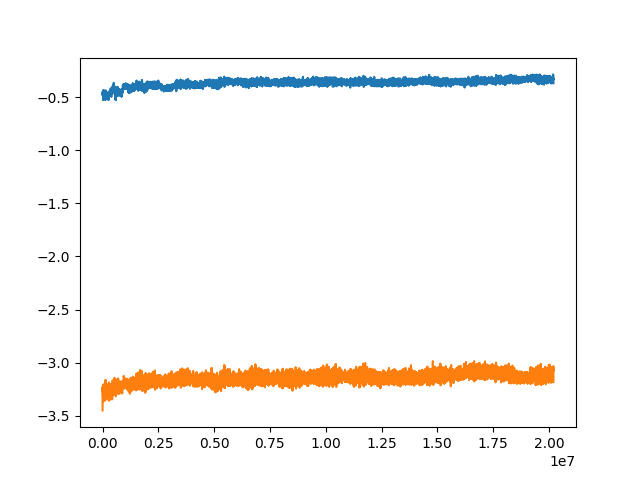

In [4]:
import matplotlib.pyplot as plt
%matplotlib widget

plt.figure()
plt.plot(del_phi0)
plt.plot(del_phi1)
plt.show()

In [5]:
# calculate the angle of arrival give the spacing between the antennas
# and the wavelength of the signal
c = 3e8
fc = 11e9
lam = c/fc
d0 = 0.135
d1 = 0.20

# converting delphi in range -pi,pi to 0,2pi
del_phi0 = np.fmod(del_phi0,2*np.pi)
del_phi0 = np.where(del_phi0<0,del_phi0+2*np.pi,del_phi0)
del_phi1 = np.fmod(del_phi1,2*np.pi)
del_phi1 = np.where(del_phi1<0,del_phi1+2*np.pi,del_phi1)

# possible range of del_phi1 and del_phi2
k0 = np.arange(0,np.round(d0/(lam/2)),1)
k1 = np.arange(0,np.round(d1/(lam/2)),1)

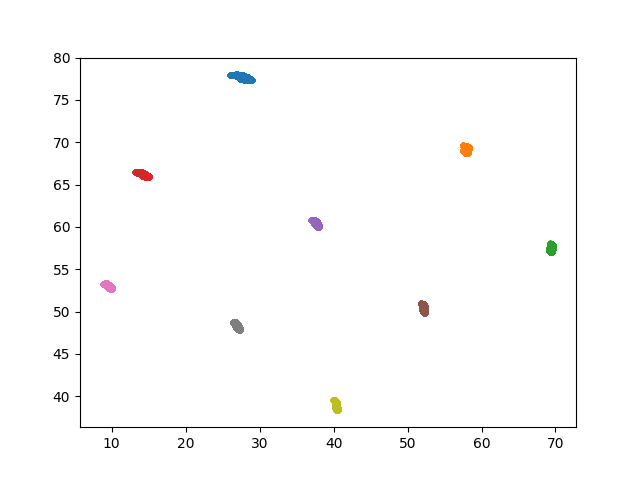

In [12]:
# calculating the angle of arrival
plt.figure()
for i in k0[0:3]:
    for j in k1[0:3]:
        phi0 = del_phi0 + 2*np.pi*i
        phi1 = del_phi1 + 2*np.pi*j
        a = (np.arctan(phi1/phi0))
        el = np.arccos(phi0*lam/(2*np.pi*d0*np.cos(a)))
        az = np.arctan2(phi1, phi0)
        
        plt.plot(np.rad2deg(az),np.rad2deg(el),'.')
plt.xlabel('Azimuth')
plt.ylabel('Elevation')

In [7]:
plt.plot(az,el,'.')